## Работа с датасетом "Rain in Australia".
Будем предсказывать класс RainTomorrow.

Гипотезы: 
1) Использование class_weight='balanced' повысит F1-score для класса RainTomorrow = Yes по сравнению с моделями без балансировки классов.
2) Использование L1-регуляризации в логистической регрессии позволит получить более высокий F1-score по сравнению с L2-регуляризацией за счёт зануления коэффициентов при избыточных признаках;
3) Sunshine, Humidity3pm, MinTemp будут наиболее важными признаками по feature importance дерева;
4) Удаление признаков с корреляцией > 0.90 улучшит F1-score логистической регрессии.
5) Использование признака Location (город) повысит качество предсказания дождя по метрике ROC-AUC для логистической регрессии и дерева решений.
6) Отбор 5 лучших признаков через SelectKBest не ухудшит F1-score дерева решений по сравнению с моделью на всех признаках.

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

d = pd.read_csv('HW/weatherAUS.csv')
d.head()

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


### EDA

In [34]:
print(d.info())
d['RainTomorrow'].isna().sum()

<class 'pandas.DataFrame'>
RangeIndex: 145460 entries, 0 to 145459
Data columns (total 23 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Date           145460 non-null  str    
 1   Location       145460 non-null  str    
 2   MinTemp        143975 non-null  float64
 3   MaxTemp        144199 non-null  float64
 4   Rainfall       142199 non-null  float64
 5   Evaporation    82670 non-null   float64
 6   Sunshine       75625 non-null   float64
 7   WindGustDir    135134 non-null  str    
 8   WindGustSpeed  135197 non-null  float64
 9   WindDir9am     134894 non-null  str    
 10  WindDir3pm     141232 non-null  str    
 11  WindSpeed9am   143693 non-null  float64
 12  WindSpeed3pm   142398 non-null  float64
 13  Humidity9am    142806 non-null  float64
 14  Humidity3pm    140953 non-null  float64
 15  Pressure9am    130395 non-null  float64
 16  Pressure3pm    130432 non-null  float64
 17  Cloud9am       89572 non-null   float64


np.int64(3267)

тк RainTomorrow - целевая переменная, то исключим 3267 пропусков в ней
также необходимо изучить пропуски в признаках и заполнить их

In [35]:
d = d.dropna(subset='RainTomorrow').reset_index(drop=True)
missing = pd.DataFrame({'cnt': d.isna().sum(), 'percent': d.isna().mean().round(4) * 100})
missing
# видно, что в Evaporation, Sunshine, Cloud9am, Cloud3pm больше всего пропусков. 
# нужно проверить, от чего они зависят. возможно от места

,cnt,percent
Date,0,0.00
Location,0,0.00
MinTemp,637,0.45
MaxTemp,322,0.23
Rainfall,1406,0.99
Evaporation,60843,42.79
Sunshine,67816,47.69
WindGustDir,9330,6.56
WindGustSpeed,9270,6.52
WindDir9am,10013,7.04


In [36]:
more_nan_cols = ['Evaporation', 'Sunshine', 'Cloud9am', 'Cloud3pm']
missing_loc = d.groupby('Location')[more_nan_cols].agg(lambda x: x.isna().mean() * 100).round(2)
missing_loc

,Evaporation,Sunshine,Cloud9am,Cloud3pm
Location,,,,
Adelaide,46.63,45.05,100.00,100.00
Albany,9.28,16.78,1.16,23.04
Albury,100.00,100.00,57.42,53.01
AliceSprings,6.96,16.86,10.95,11.81
BadgerysCreek,100.00,100.00,100.00,100.00
Ballarat,100.00,100.00,17.97,34.38
Bendigo,60.94,100.00,31.77,25.28
Brisbane,0.60,1.52,0.03,0.06
Cairns,11.41,14.26,6.19,6.89


можно заметить, что у некоторых точек вообще отсутствует информация об этих признаках.
малое и среднее количество пропусков можно заполнить медианой
полное количество пропусков заполнить либо общей медианой, либо удалить признаки

In [37]:
d.describe().round(2)

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm
count,141556.00,141871.00,140787.00,81350.00,74377.00,132923.00,140845.00,139563.00,140419.00,138583.00,128179.00,128212.00,88536.00,85099.00,141289.00,139467.00
mean,12.19,23.23,2.35,5.47,7.62,39.98,14.00,18.64,68.84,51.48,1017.65,1015.26,4.44,4.50,16.99,21.69
std,6.40,7.12,8.47,4.19,3.78,13.59,8.89,8.80,19.05,20.80,7.11,7.04,2.89,2.72,6.49,6.94
min,-8.50,-4.80,0.00,0.00,0.00,6.00,0.00,0.00,0.00,0.00,980.50,977.10,0.00,0.00,-7.20,-5.40
25%,7.60,17.90,0.00,2.60,4.90,31.00,7.00,13.00,57.00,37.00,1012.90,1010.40,1.00,2.00,12.30,16.60
50%,12.00,22.60,0.00,4.80,8.50,39.00,13.00,19.00,70.00,52.00,1017.60,1015.20,5.00,5.00,16.70,21.10
75%,16.80,28.20,0.80,7.40,10.60,48.00,19.00,24.00,83.00,66.00,1022.40,1020.00,7.00,7.00,21.60,26.40
max,33.90,48.10,371.00,145.00,14.50,135.00,130.00,87.00,100.00,100.00,1041.00,1039.60,9.00,9.00,40.20,46.70


видно выбросы в Rainfall, Evaporation

### Распределение классов

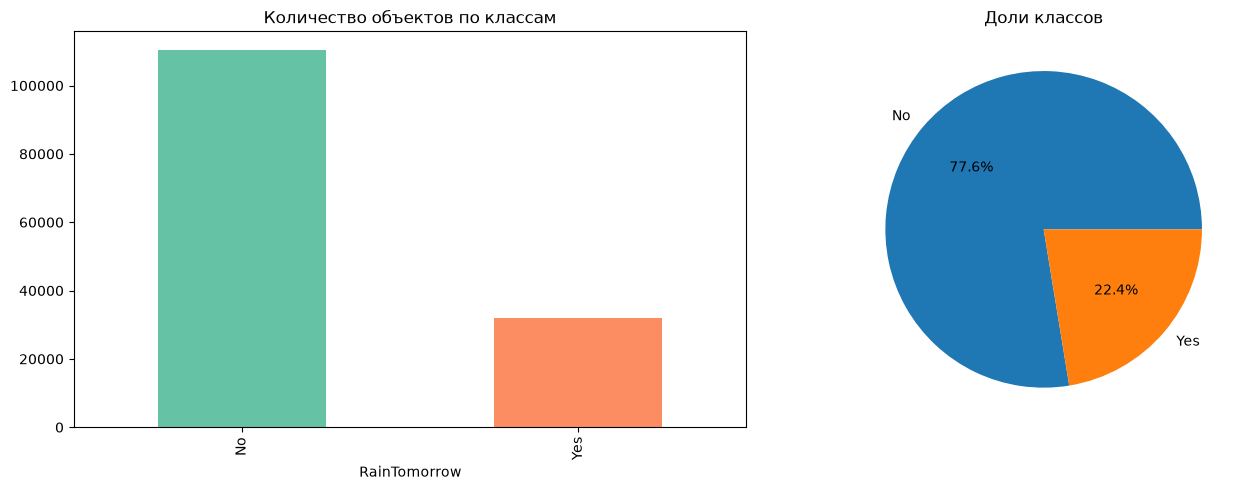

In [38]:
target_col_name = 'RainTomorrow'
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
d[target_col_name].value_counts().plot.bar(ax=ax[0], color=sns.color_palette('Set2'))
ax[0].set_title('Количество объектов по классам')
d[target_col_name].value_counts().plot.pie(ax=ax[1], autopct='%1.1f%%', color=sns.color_palette('Set2'))
ax[1].set_title('Доли классов')
plt.tight_layout()
plt.show()

Видим существенный дисбаланс классов 

### Распределение признаков

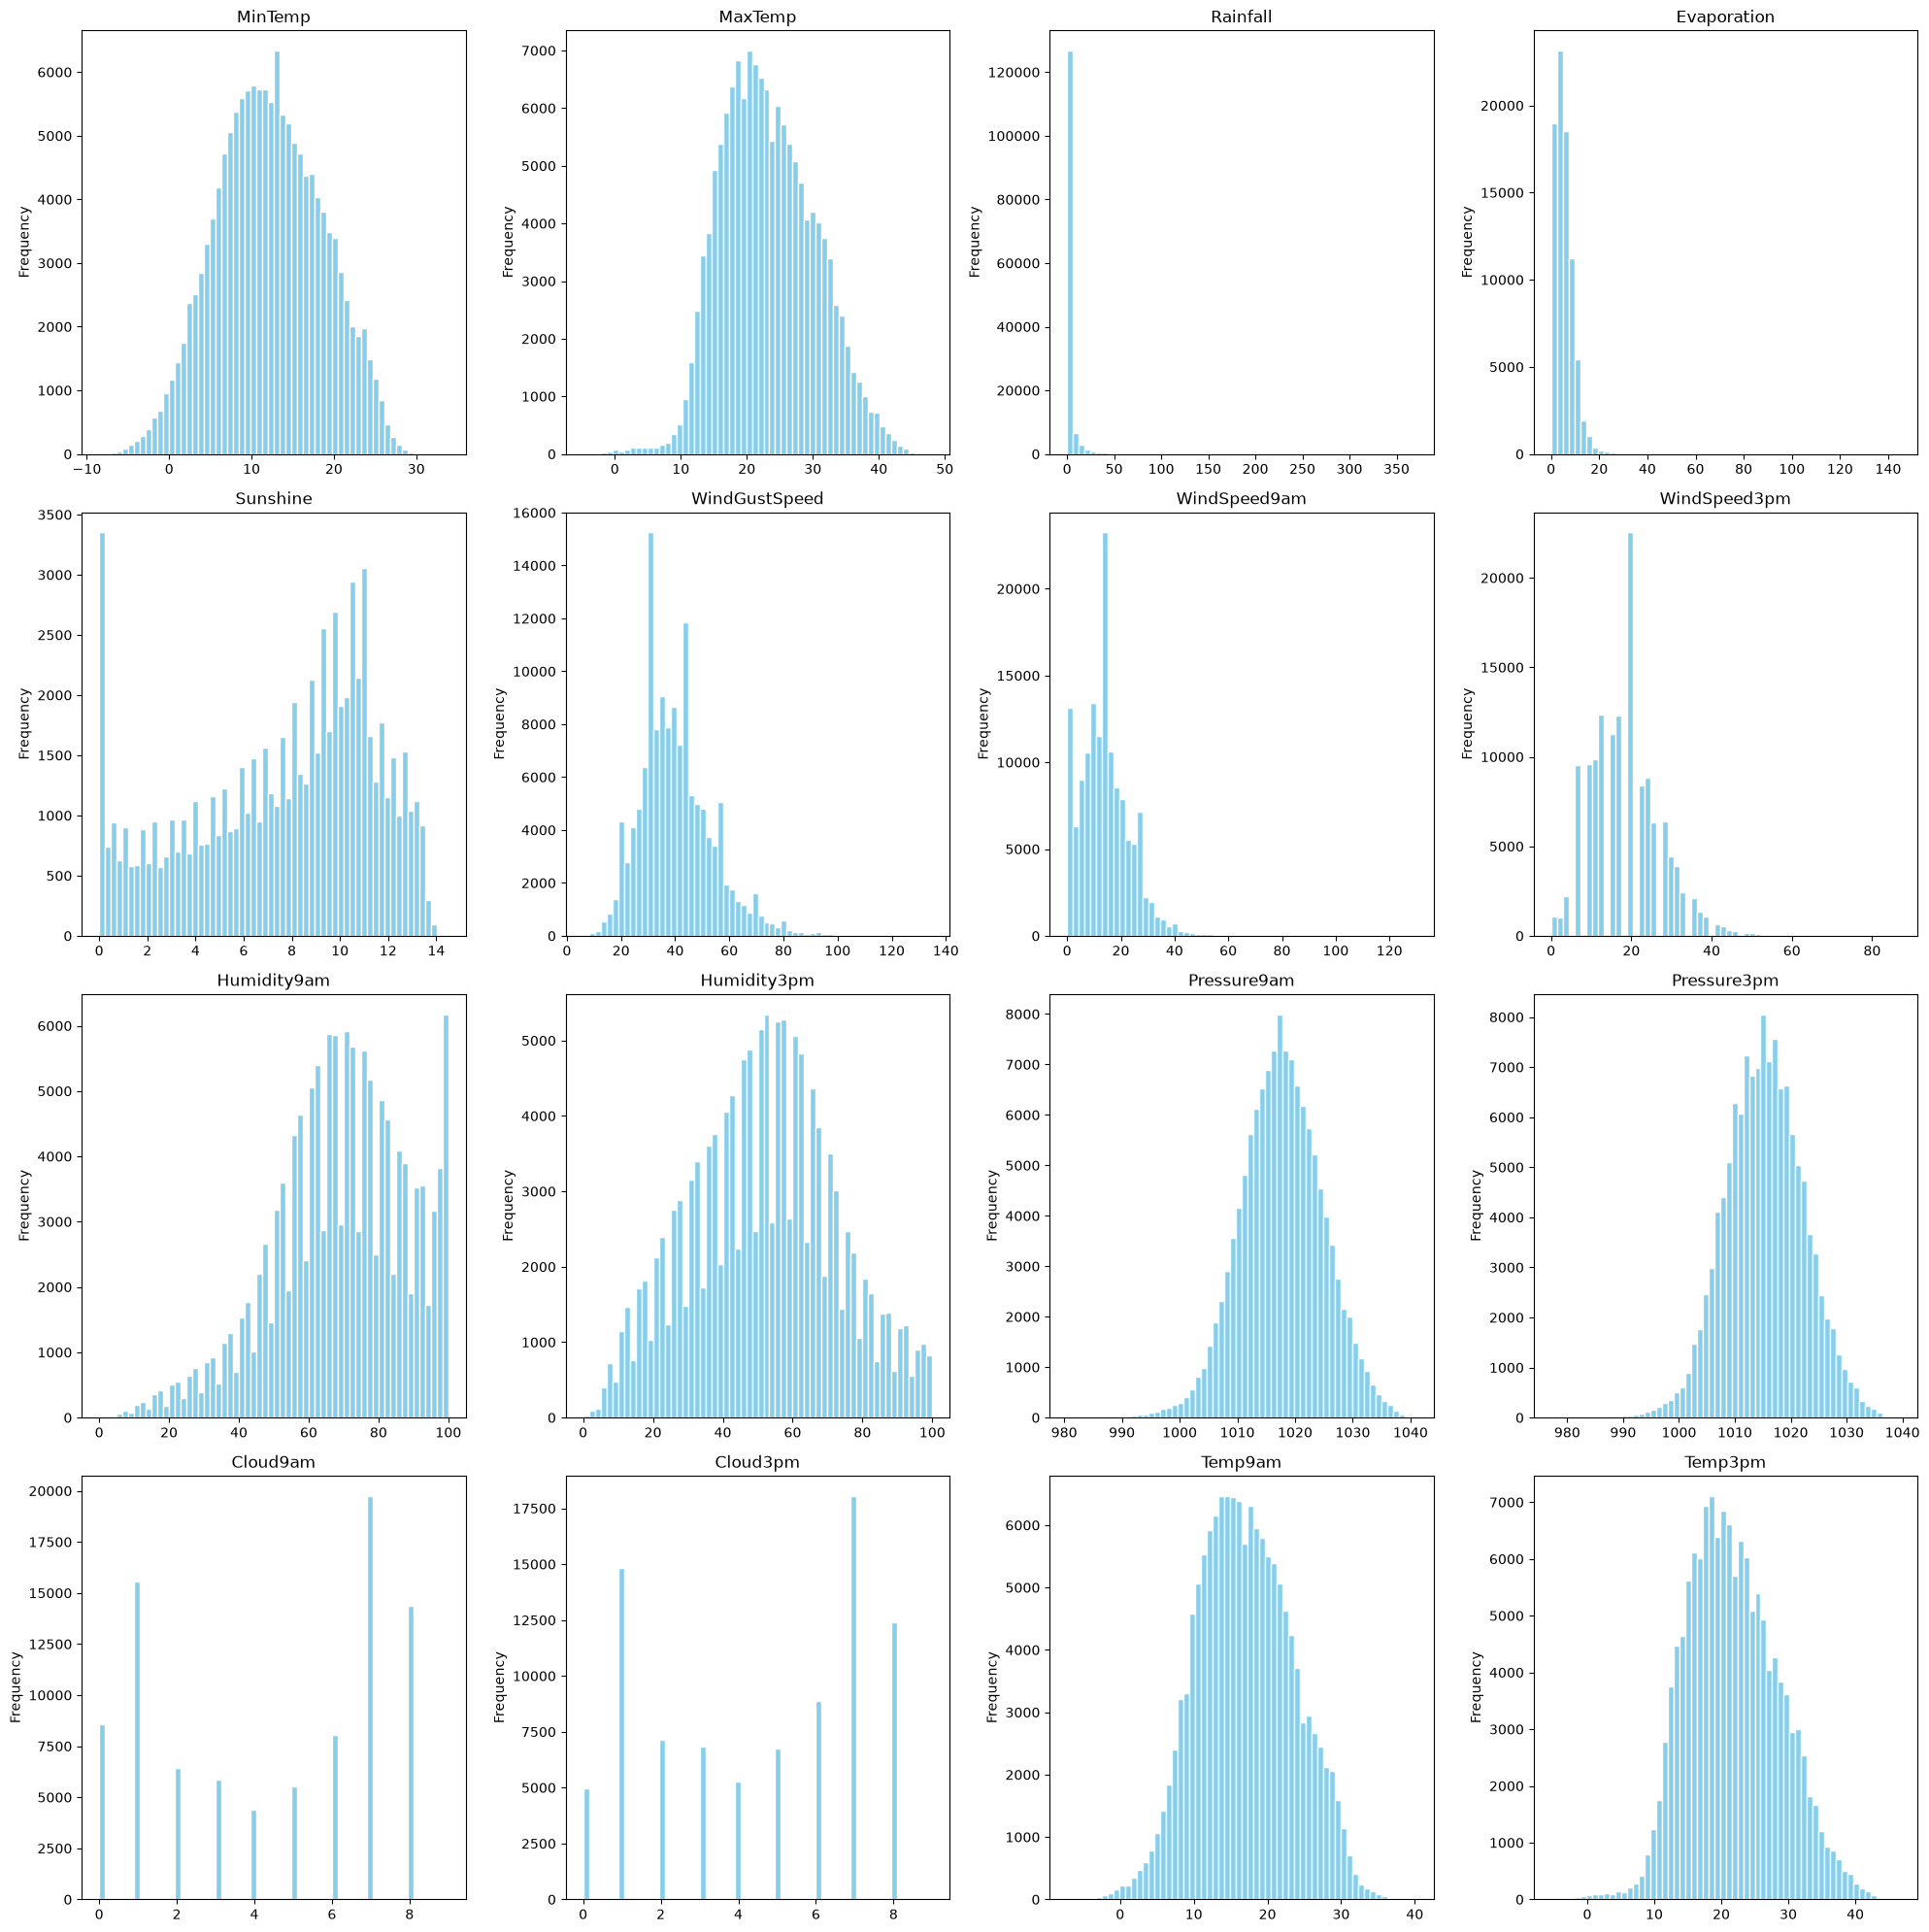

In [39]:
# в этих признаках выбросы растягиваются до 300
# problem_col = ['Rainfall', 'Evaporation']
# d = d[(d[problem_col] < 140).all(axis=1)].reset_index(drop=True)
numeric_cols = d.select_dtypes(include=np.number).columns.tolist()
fig, axes = plt.subplots(len(numeric_cols) // 4, 4, figsize=(20, 20))
axes = axes.flatten()

for i, j in zip(axes, numeric_cols):
    d[j].plot.hist(bins=60, ax=i, color='skyblue', edgecolor='white')
    i.set_title(j)
plt.tight_layout()
plt.show()

### Корреляционная матрица


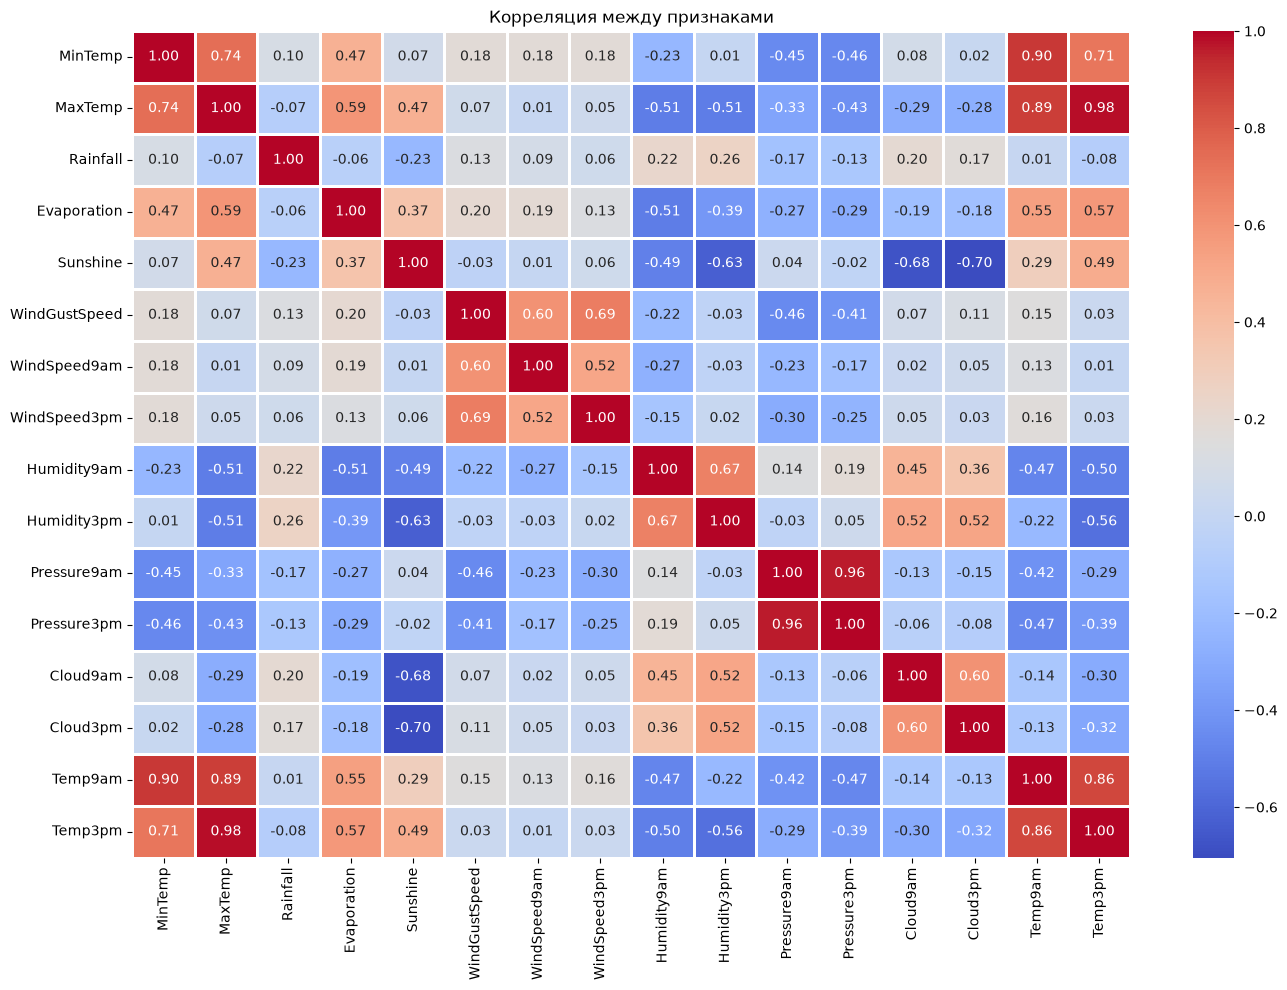

In [40]:
plt.figure(figsize=(14, 10))
corr = d[numeric_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', linewidths=1)
plt.title('Корреляция между признаками')
plt.tight_layout()
plt.show()

### Boxplot признаков по классам


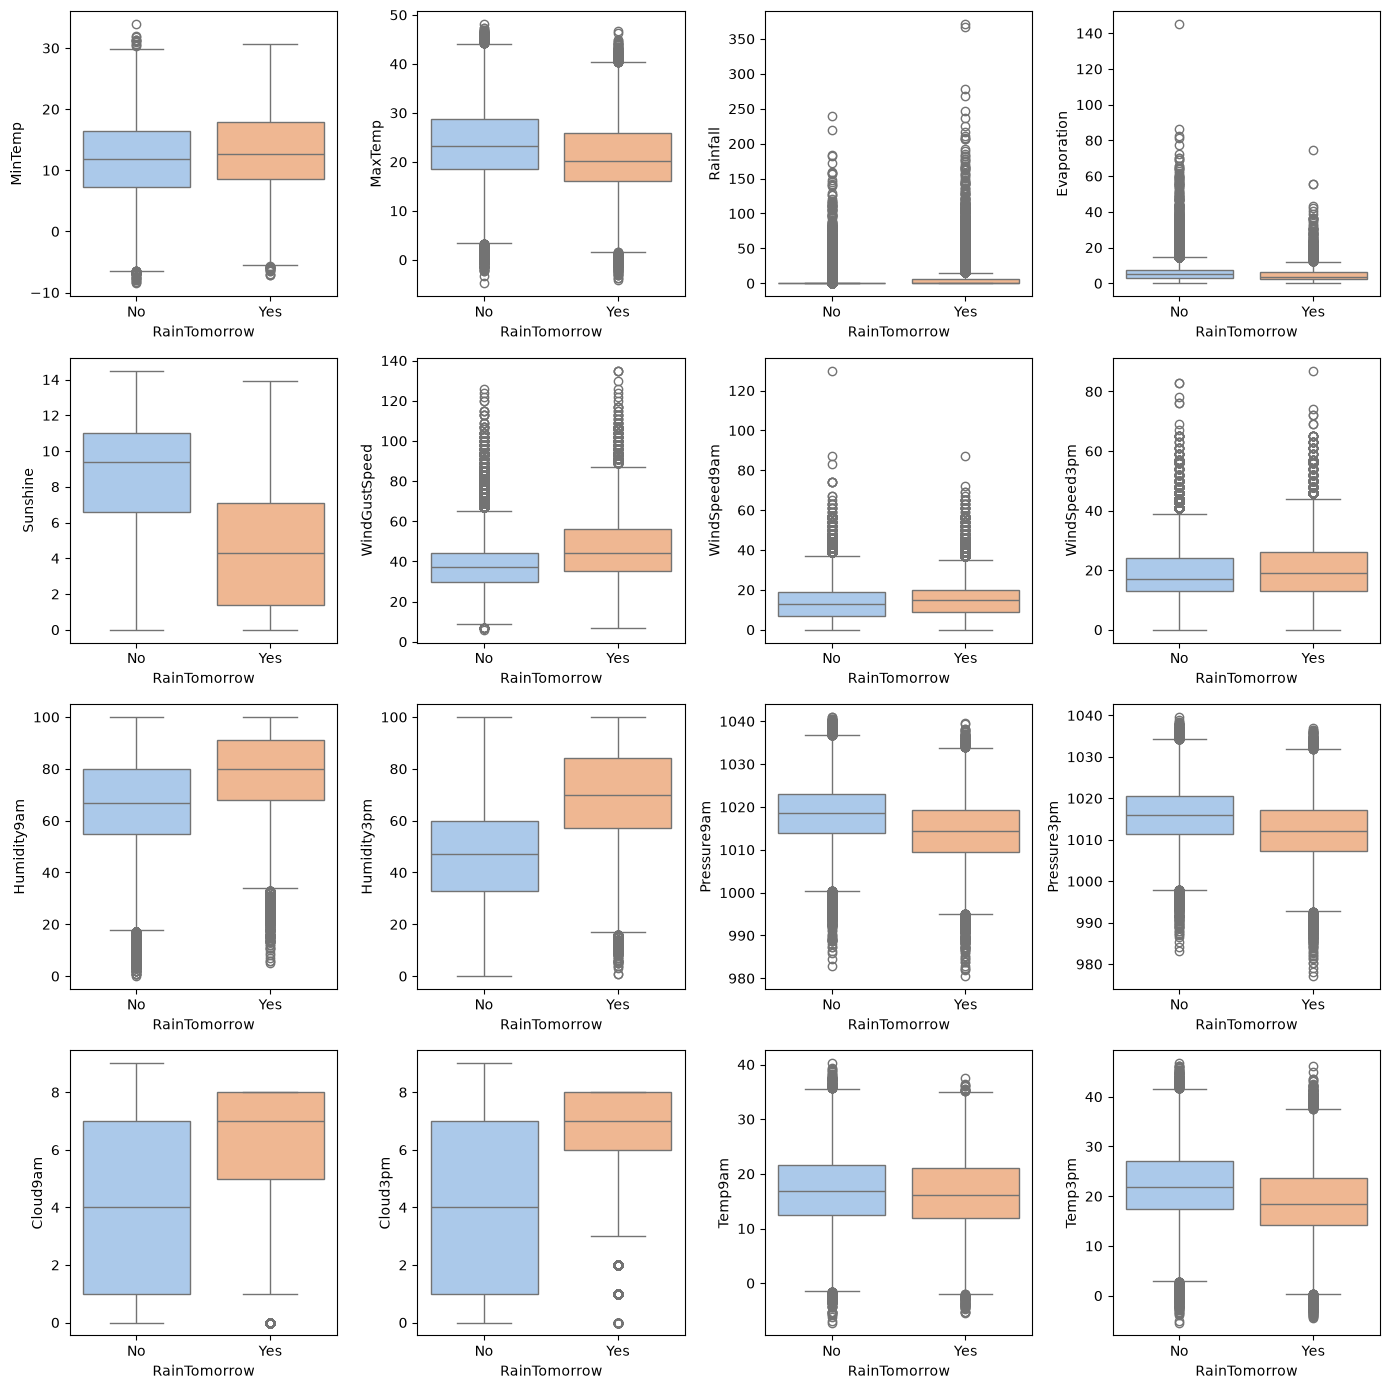

In [41]:
fig, axes = plt.subplots(4, 4, figsize=(14, 14))
axes = axes.flatten()
for i, j in zip(axes, numeric_cols):
    sns.boxplot(data=d, x='RainTomorrow', hue='RainTomorrow', y=j, ax=i, palette='pastel')
plt.tight_layout()
plt.show()

### Pairplot 

In [42]:
# target_col = 'RainTomorrow'
# sns.pairplot(d[['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustSpeed', 'Humidity9am', 'Pressure9am', 'Cloud9am', 'Cloud3pm', 'Temp3pm', target_col]], hue=target_col, palette='Set2', plot_kws={'alpha': 0.4, 's': 15})
# plt.show()
# долго грузит

### Подготовка данных
1) Убрать пропуски без утечки данных

In [43]:
from sklearn.model_selection import train_test_split

X_all = d.drop(columns=['Date']).copy()

X_cls = X_all.drop(columns='RainTomorrow')
y_cls = X_all['RainTomorrow']

X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_cls, y_cls, train_size=0.8, random_state=12, stratify=y_cls
)

X_filled_train = X_train_cls.copy()
X_filled_test = X_test_cls.copy()

cat_cols = ['WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday', 'Location']

for col in numeric_cols:
    loc_median = X_filled_train.groupby('Location')[col].median()
    global_median = X_filled_train[col].median()

    X_filled_train[col] = X_filled_train[col].fillna(X_filled_train['Location'].map(loc_median))
    X_filled_test[col] = X_filled_test[col].fillna(X_test_cls['Location'].map(loc_median))
    
    X_filled_train[col] = X_filled_train[col].fillna(global_median)
    X_filled_test[col] = X_filled_test[col].fillna(global_median)

for col in cat_cols:
    
    loc_mode = X_filled_train.groupby('Location')[col].agg(lambda x: x.mode().iloc[0] if not x.mode().empty else None)
    global_mode = X_filled_train[col].mode().iloc[0]
    
    X_filled_train[col] = X_filled_train[col].fillna(X_filled_train['Location'].map(loc_mode))
    X_filled_train[col] = X_filled_train[col].fillna(global_mode)
    
    X_filled_test[col] = X_filled_test[col].fillna(X_test_cls['Location'].map(loc_mode))
    X_filled_test[col] = X_filled_test[col].fillna(global_mode)
    
# исходные данные с пропусками оставляем для CV
# заполненные копии используем для первых моделей
nans = X_filled_train.isna().sum().sum()
nans

np.int64(0)

2. Кодировка категориальных признаков и целевой переменной 

In [44]:
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

le = LabelEncoder()

y_train_cls = le.fit_transform(y_train_cls)
y_test_cls = le.transform(y_test_cls)

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
        ('num', StandardScaler(), numeric_cols)
    ]
)

X_train_ready = preprocessor.fit_transform(X_filled_train)
X_test_ready = preprocessor.transform(X_filled_test)


### Логистическая регрессия без и с class_weight='balanced'

In [45]:
from sklearn.linear_model import LogisticRegression

l2_model_without_balance = LogisticRegression(solver='saga', max_iter=1000, random_state=12)
l2_model_with_balance = LogisticRegression(solver='saga', max_iter=1000, random_state=12, class_weight='balanced')

l1_model_without_balance = LogisticRegression(solver='saga', l1_ratio=1.0, max_iter=1000, random_state=12)
l1_model_with_balance = LogisticRegression(solver='saga', l1_ratio=1.0, class_weight='balanced', max_iter=1000, random_state=12)

l2_model_without_balance.fit(X_train_ready, y_train_cls)
l2_model_with_balance.fit(X_train_ready, y_train_cls)

l1_model_without_balance.fit(X_train_ready, y_train_cls)
l1_model_with_balance.fit(X_train_ready, y_train_cls)


,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",1.0
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",12
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'saga'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the so

### Метрики

In [46]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score)

def metrics(model, X, y):
    y_pred = model.predict(X)
    y_proba = model.predict_proba(X)[:, 1]
    
    return {
        'Accuracy': accuracy_score(y, y_pred),
        'Precision': precision_score(y, y_pred),
        'Recall': recall_score(y, y_pred),
        'F1-score': f1_score(y, y_pred),
        'ROC-AUC': roc_auc_score(y, y_proba),
        'AP': average_precision_score(y, y_proba)
    }

models = {
    'L2 without balance': l2_model_without_balance,
    'L2 with balance': l2_model_with_balance,
    'L1 without balance': l1_model_without_balance,
    'L1 with balance': l1_model_with_balance
}

res = {}

for name, model in models.items():
    res[name] = metrics(model, X_test_ready, y_test_cls)

res_df = pd.DataFrame(res).T
display(res_df)

,Accuracy,Precision,Recall,F1-score,ROC-AUC,AP
L2 without balance,0.851436,0.740815,0.518745,0.610204,0.874377,0.710728
L2 with balance,0.796863,0.531958,0.780706,0.632763,0.874772,0.707524
L1 without balance,0.851507,0.741147,0.518745,0.610317,0.874388,0.710733
L1 with balance,0.796969,0.532101,0.781333,0.633071,0.874780,0.707534


До подбора параметров F1 выше у моделей с балансировкой, а L1 немного лучше L2. Пока результаты подтверждают гипотезы 1 и 2, но нужно проверить их на CV.

Самый высокий Precision у L1 без балансировки (0.7411), те около 74% предупреждений о дожде верны. Recall выше у L1 с балансировкой (0.7813), те модель нашла около 78% дождливых дней. Значит, балансировка помогает пропускать меньше дождей, но доля ложных предупреждений становится больше.

### Класс CityNanFilled
для пайплайна чтобы сделать замены по городам


In [47]:
from sklearn.base import BaseEstimator, TransformerMixin

class CityNanFilled(TransformerMixin, BaseEstimator):
    def __init__(self, num_cols, cat_cols):
        self.num_cols = num_cols
        self.cat_cols = cat_cols
        
        
    def fit(self, X, y=None): 
        
        self.city_medians = {}
        self.global_medians = {}
        self.city_modes = {}
        self.global_modes = {}
        
        X_filled_for_cv = X.copy()

        for col in self.num_cols:
            if col == 'Location':
                continue
            loc_median = X_filled_for_cv.groupby('Location')[col].median()
            global_median = X_filled_for_cv[col].median()
            
            self.city_medians[col] = loc_median
            self.global_medians[col] = global_median
            
        for col in self.cat_cols:
            if col == 'Location':
                continue
            loc_mode = X_filled_for_cv.groupby('Location')[col].agg(lambda x: x.mode().iloc[0] if not x.mode().empty else None)
            global_mode = X_filled_for_cv[col].mode().iloc[0]   
              
            self.city_modes[col] = loc_mode
            self.global_modes[col] = global_mode
            
        return self
            
            
    def transform(self, X):
        X_filled = X.copy()
        
        for col, v in self.city_medians.items():
            X_filled[col] = X_filled[col].fillna(X_filled['Location'].map(v))
        
        for col, v in self.global_medians.items():
            X_filled[col] = X_filled[col].fillna(v)
        
        for col, v in self.city_modes.items():
            X_filled[col] = X_filled[col].fillna(X_filled['Location'].map(v))
            
        for col, v in self.global_modes.items():
            X_filled[col] = X_filled[col].fillna(v)  
        
        return X_filled

### Pipeline, разделение, кросс-валидация

#### 1 модель - l2_model_without_balance

In [48]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate

pipe1 = Pipeline([
    ('NanFilling', CityNanFilled(numeric_cols, cat_cols)),
    ('preprocessor', preprocessor),
    ('model', l2_model_without_balance)
])

scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'average_precision']

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=12)

res_cv1 = cross_validate(pipe1, X_train_cls, y_train_cls, cv=cv, scoring=scoring)

print('Средние по метрикам до подбора гиперпараметров у модели L2 без балансировки')
print()
for metric in scoring:
    print(metric, res_cv1['test_' + metric].mean().round(4))

Средние по метрикам до подбора гиперпараметров у модели L2 без балансировки

accuracy 0.8474
precision 0.7286
recall 0.5087
f1 0.5991
roc_auc 0.8696
average_precision 0.7029


#### 2 модель - l2_model_with_balance

In [49]:
pipe2 = Pipeline([
    ('NanFilling', CityNanFilled(numeric_cols, cat_cols)),
    ('preprocessor', preprocessor),
    ('model', l2_model_with_balance)
])

res_cv2 = cross_validate(pipe2, X_train_cls, y_train_cls, cv=cv, scoring=scoring)

print('Средние по метрикам до подбора гиперпараметров у модели L2 с балансировкой')
print()
for metric in scoring:
    print(metric, res_cv2['test_' + metric].mean().round(4))

Средние по метрикам до подбора гиперпараметров у модели L2 с балансировкой

accuracy 0.7938
precision 0.5274
recall 0.7733
f1 0.6271
roc_auc 0.8702
average_precision 0.6995


У L2 с балансировкой Precision снизился с 0.7286 до 0.5274, а Recall вырос с 0.5087 до 0.7733. Те модель находит около 77% дождливых дней вместо 51%, но только около 53% предупреждений о дожде верны. F1 вырос с 0.5991 до 0.6271, гипотеза 1 для L2 подтвердилась.

#### 3 модель - l1_model_without_balance

In [50]:
pipe3 = Pipeline([
    ('NanFilling', CityNanFilled(numeric_cols, cat_cols)),
    ('preprocessor', preprocessor),
    ('model', l1_model_without_balance)
])

res_cv3 = cross_validate(pipe3, X_train_cls, y_train_cls, cv=cv, scoring=scoring)

print('Средние по метрикам до подбора гиперпараметров у модели L1 без балансировки')
print()
for metric in scoring:
    print(metric, res_cv3['test_' + metric].mean().round(4))

Средние по метрикам до подбора гиперпараметров у модели L1 без балансировки

accuracy 0.8474
precision 0.7288
recall 0.5084
f1 0.599
roc_auc 0.8696
average_precision 0.7029


#### 4 модель - l1_model_with_balance

In [51]:
pipe4 = Pipeline([
    ('NanFilling', CityNanFilled(numeric_cols, cat_cols)),
    ('preprocessor', preprocessor),
    ('model', l1_model_with_balance)
])

res_cv4 = cross_validate(pipe4, X_train_cls, y_train_cls, cv=cv, scoring=scoring)

print('Средние по метрикам до подбора гиперпараметров у модели L1 c балансировкой')
print()
for metric in scoring:
    print(metric, res_cv4['test_' + metric].mean().round(4))

Средние по метрикам до подбора гиперпараметров у модели L1 c балансировкой

accuracy 0.7938
precision 0.5273
recall 0.7732
f1 0.627
roc_auc 0.8702
average_precision 0.6995


1 гипотеза подтвердилась и для L1: F1 с балансировкой (0.6270) выше, чем без нее (0.5990).

2 гипотеза на CV не подтвердилась: F1 у L1 с балансировкой (0.6270) немного ниже, чем у L2 (0.6271). Разница очень небольшая. Самый высокий Precision среди четырех моделей на CV у L1 без балансировки (0.7288), а Recall — у L2 с балансировкой (0.7733).

### Подбор гиперпараметров

#### 1) l2_model_without_balance

In [52]:
from sklearn.model_selection import GridSearchCV

C_GRID = [0.01, 0.1, 1, 10]
PARAM_GRID = {"model__C": C_GRID, 'model__max_iter': [2000]}

gscv1 = GridSearchCV(estimator=pipe1, param_grid=PARAM_GRID, cv=cv, scoring=scoring, refit='f1')
res_grid1 = gscv1.fit(X_train_cls, y_train_cls)

print(gscv1.best_params_)
print(gscv1.best_score_)

/Users/nastya/Desktop/эмэл/.venv/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/nastya/Desktop/эмэл/.venv/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/nastya/Desktop/эмэл/.venv/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/nastya/Desktop/эмэл/.venv/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/nastya/Desktop/эмэл/.venv/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/nastya/D

{'model__C': 10, 'model__max_iter': 2000}
0.5991538389346915


#### 2) l2_model_with_balance

In [53]:
gscv2 = GridSearchCV(estimator=pipe2, param_grid=PARAM_GRID, cv=cv, scoring=scoring, refit='f1')
res_grid1 = gscv2.fit(X_train_cls, y_train_cls)

print(gscv2.best_params_)
print(gscv2.best_score_)

{'model__C': 1, 'model__max_iter': 2000}
0.627103503183042


После подбора параметров 1 гипотеза для L2 снова подтвердилась: F1 на CV с балансировкой (0.6271) выше, чем без нее (0.5992).

#### 3) l1_model_without_balance

In [54]:
gscv3 = GridSearchCV(estimator=pipe3, param_grid=PARAM_GRID, cv=cv, scoring=scoring, refit='f1')
res_grid1 = gscv3.fit(X_train_cls, y_train_cls)

print(gscv3.best_params_)
print(gscv3.best_score_)

{'model__C': 10, 'model__max_iter': 2000}
0.599139507581383


#### 4) l1_model_with_balance

In [55]:
gscv4 = GridSearchCV(estimator=pipe4, param_grid=PARAM_GRID, cv=cv, scoring=scoring, refit='f1')
res_grid1 = gscv4.fit(X_train_cls, y_train_cls)

print(gscv4.best_params_)
print(gscv4.best_score_)

{'model__C': 10, 'model__max_iter': 2000}
0.6270280314107903


Для L1 1 гипотеза тоже подтвердилась: F1 на CV вырос с 0.5991 без балансировки до 0.6270 с ней.

2 гипотеза не подтвердилась: после подбора параметров F1 у L1 с балансировкой (0.627028) немного ниже, чем у L2 (0.627104).

#### Метрики полной L2-модели после подбора параметров
Эти метрики нужны для сравнения с моделями без трех признаков и без Location.

In [56]:
res_full_l2 = pd.DataFrame({
    'L2 после GridSearchCV': metrics(gscv2.best_estimator_, X_test_cls, y_test_cls)
}).T
display(res_full_l2)

,Accuracy,Precision,Recall,F1-score,ROC-AUC,AP
L2 после GridSearchCV,0.796863,0.531958,0.780706,0.632763,0.874772,0.707524


#### Проверка 4 гипотезы
Возьму L2 с балансировкой. У модели без трех признаков оставлю те же параметры, что у полной модели, чтобы сравнить влияние удаления признаков.

In [57]:
from sklearn.base import clone

cols_high_corr = ['Temp9am', 'Temp3pm', 'Pressure3pm']

X_train_corr = X_filled_train.drop(columns=cols_high_corr)
X_test_corr = X_filled_test.drop(columns=cols_high_corr)
numeric_cols2 = X_train_corr.select_dtypes(include=np.number).columns.tolist()

preprocessor2 = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
        ('num', StandardScaler(), numeric_cols2)
    ]
)

X_train_corr = preprocessor2.fit_transform(X_train_corr)
X_test_corr = preprocessor2.transform(X_test_corr)

l2_model_with_balance_corr = clone(gscv2.best_estimator_.named_steps['model'])
l2_model_with_balance_corr.fit(X_train_corr, y_train_cls)

res2 = {}

res2['L2 без 3 признаков'] = metrics(l2_model_with_balance_corr, X_test_corr, y_test_cls)

res_df2 = pd.DataFrame(res2).T
display(res_df2)



,Accuracy,Precision,Recall,F1-score,ROC-AUC,AP
L2 без 3 признаков,0.79289,0.525691,0.778353,0.627545,0.870817,0.702734


4 гипотеза не подтвердилась: после удаления Temp9am, Temp3pm и Pressure3pm F1 снизился с 0.632763 до 0.627545, те баланс Precision и Recall стал немного хуже. ROC-AUC тоже снизился с 0.874772 до 0.870817, те модель стала немного хуже различать дождливые и недождливые дни по предсказанным вероятностям. Значит, удаление этих признаков не улучшило качество L2-модели.

#### Проверка 5 гипотезы для L2 с балансировкой
Уберем Location из признаков модели. Для заполнения пропусков город по-прежнему используется, те здесь проверяется именно польза Location как входного признака.

In [58]:
X_train_no_loc = X_filled_train.drop(columns=['Location'])
X_test_no_loc = X_filled_test.drop(columns=['Location'])

cat_cols_no_loc = ['WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday']

preprocessor_no_loc = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols_no_loc),
        ('num', StandardScaler(), numeric_cols)
    ]
)

X_train_no_loc = preprocessor_no_loc.fit_transform(X_train_no_loc)
X_test_no_loc = preprocessor_no_loc.transform(X_test_no_loc)

l2_model_with_balance_loc = clone(gscv2.best_estimator_.named_steps['model'])
l2_model_with_balance_loc.fit(X_train_no_loc, y_train_cls)

res3 = {}

res3['L2 без Location'] = metrics(l2_model_with_balance_loc, X_test_no_loc, y_test_cls)

res_df3 = pd.DataFrame(res3).T
display(res_df3)

,Accuracy,Precision,Recall,F1-score,ROC-AUC,AP
L2 без Location,0.790007,0.521195,0.777255,0.623977,0.869254,0.692284


Без Location ROC-AUC снизился с 0.874772 до 0.869254, а F1 с 0.632763 до 0.623977. Значит, Location немного улучшает качество L2-модели, для нее 5 гипотеза подтвердилась. Precision и Recall тоже немного снизились.

### Дерево решений

In [59]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=12)

tree.fit(X_train_ready, y_train_cls)

res4 = {}

res4['Дерево решений'] = metrics(tree, X_test_ready, y_test_cls)

res_df4 = pd.DataFrame(res4).T
display(res_df4)

,Accuracy,Precision,Recall,F1-score,ROC-AUC,AP
Дерево решений,0.790745,0.532376,0.546824,0.539503,0.704143,0.392847


#### Подбор параметров

In [60]:
param_grid_tree = {
    'model__max_depth': [5, 10, 15, 20],
    'model__min_samples_split': [2, 10, 20],
    'model__min_samples_leaf': [1, 5, 10],
    'model__class_weight': [None, 'balanced']
}

# вся подготовка обучается внутри каждого фолда
pipe_tree = Pipeline([
    ('NanFilling', CityNanFilled(numeric_cols, cat_cols)),
    ('preprocessor', clone(preprocessor)),
    ('model', DecisionTreeClassifier(random_state=12))
])

grid_tree = GridSearchCV(
    estimator=pipe_tree, param_grid=param_grid_tree,
    scoring='f1', cv=cv, n_jobs=-1
)
grid_tree.fit(X_train_cls, y_train_cls)
print('Лучшие параметры:', grid_tree.best_params_)
print('Лучший F1 на CV:', grid_tree.best_score_)

best_tree = grid_tree.best_estimator_
res5 = {'Дерево после GridSearchCV': metrics(best_tree, X_test_cls, y_test_cls)}
res_df5 = pd.DataFrame(res5).T
display(res_df5)


Лучшие параметры: {'model__class_weight': 'balanced', 'model__max_depth': 10, 'model__min_samples_leaf': 5, 'model__min_samples_split': 2}
Лучший F1 на CV: 0.598700977917958


,Accuracy,Precision,Recall,F1-score,ROC-AUC,AP
Дерево после GridSearchCV,0.766799,0.48721,0.767843,0.596152,0.846421,0.66458


После подбора параметров F1 дерева вырос с 0.5395 до 0.5962, а ROC-AUC с 0.7041 до 0.8464. Значит, по этим метрикам качество стало лучше.

Recall вырос с 0.5468 до 0.7678, те дерево стало находить около 77% дождливых дней вместо 55%. Но Precision снизился с 0.5324 до 0.4872, те теперь меньше половины предупреждений о дожде верны.

#### Проверим 5 гипотезу для дерева

In [61]:
tree_no_loc = clone(best_tree.named_steps['model'])

tree_no_loc.fit(X_train_no_loc, y_train_cls)

res6 = {}

res6['Дерево без Location'] = metrics(tree_no_loc, X_test_no_loc, y_test_cls)

res_df6 = pd.DataFrame(res6).T
display(res_df6)

,Accuracy,Precision,Recall,F1-score,ROC-AUC,AP
Дерево без Location,0.785646,0.515228,0.740392,0.607621,0.848575,0.667556


Без Location ROC-AUC дерева вырос с 0.846421 до 0.848575, а F1 с 0.596152 до 0.607621. Для дерева 5 гипотеза не подтвердилась, те в целом она подтвердилась только для логистической регрессии.

Precision вырос с 0.4872 до 0.5152, а Recall снизился с 0.7678 до 0.7404. Те доля верных предупреждений стала выше, но дерево стало пропускать больше дождливых дней.

#### Важные признаки (проверка 3 гипотезы)

In [62]:
importance = pd.Series(
    best_tree.named_steps['model'].feature_importances_,
    index=best_tree.named_steps['preprocessor'].get_feature_names_out()
)

importance = importance.sort_values(ascending=False)

display(importance.head(10))

num__Humidity3pm      0.562552
num__Sunshine         0.112939
num__Pressure3pm      0.101430
num__WindGustSpeed    0.078336
num__Rainfall         0.029501
num__Pressure9am      0.011719
num__MinTemp          0.009485
num__Temp9am          0.009409
num__Humidity9am      0.009366
num__Temp3pm          0.009173
dtype: float64

3 гипотеза не подтвердилась полностью: самыми важными признаками оказались Humidity3pm (0.562552), Sunshine (0.112939) и Pressure3pm (0.101430). Первые два совпали с предположением, но вместо MinTemp в тройку вошел Pressure3pm.

#### Отбор признаков (проверка 6 гипотезы)
Оставим 5 лучших признаков по f_classif через SelectKBest. Параметры дерева возьмем из GridSearchCV, чтобы сравнить с полным набором при одинаковых настройках.

In [63]:
from sklearn.feature_selection import SelectKBest, f_classif

pipe_selected = Pipeline([
    ('NanFilling', clone(best_tree.named_steps['NanFilling'])),
    ('preprocessor', clone(best_tree.named_steps['preprocessor'])),
    ('selection', SelectKBest(score_func=f_classif, k=5)),
    ('model', clone(best_tree.named_steps['model']))
])
pipe_selected.fit(X_train_cls, y_train_cls)
res7 = {'Дерево с отбором признаков': metrics(pipe_selected, X_test_cls, y_test_cls)}
res_df7 = pd.DataFrame(res7).T
display(res_df7)


,Accuracy,Precision,Recall,F1-score,ROC-AUC,AP
Дерево с отбором признаков,0.759415,0.476287,0.735686,0.578227,0.827855,0.623477


6 гипотеза не подтвердилась: после отбора 5 признаков F1 снизился с 0.596152 до 0.578227, а ROC-AUC с 0.846421 до 0.827855. Значит, отбор признаков ухудшил качество дерева.

Precision снизился с 0.4872 до 0.4763, а Recall с 0.7678 до 0.7357. Те дерево стало находить меньше дождливых дней, а доля верных предупреждений тоже уменьшилась.